# 01. Curated program-effect temporal map

This notebook loads the cNMF target-program effect spreadsheet and generates the main program-first maps. It keeps the analysis tied to expert-annotated cNMF programs.

In [1]:

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram
from scipy.spatial.distance import pdist
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

try:
    from adjustText import adjust_text
    HAS_ADJUST_TEXT = True
except Exception:
    HAS_ADJUST_TEXT = False

pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 80)
plt.rcParams['svg.fonttype'] = 'none'   # keep text editable in Illustrator
plt.rcParams['pdf.fonttype'] = 42       # keep text editable in Illustrator
plt.rcParams['font.family'] = 'DejaVu Sans'


In [2]:

# ==============================
# User settings
# ==============================
CNMF_XLSX = "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/data/cNMF_50_0_2_032526_6co.xlsx"
ASSOC_SHEET = "Perturbation Association 1"
PROGRAM_ANNOTATION_CSV = "curated_program_annotations_from_uploaded_sheet.csv"

OUTDIR = "outputs_program_level_temporal_map_v4"
os.makedirs(OUTDIR, exist_ok=True)

# Statistical thresholds for program effect significance.
FDR_CUTOFF = 0.05
EFFECT_CUTOFF = 0.0  # set to e.g. 0.15 or 0.25 if you want stricter tags

# Target groups for focused figures.
HIPPO_TARGETS = ["NF2", "LATS2", "SAV1", "TAOK1", "AMOTL2"]
BMP_TGF_TARGETS = ["SMAD1", "SMAD4", "SMAD5", "LEMD3", "BMPR1A", "ACVR2A", "ACVR1B", "ACVR2B"]
EC_TARGETS = ["KDR", "ETV2", "ERG", "FLI1", "TAL1", "CDH5", "SOX17"]

# Program axes requested by Jesse/Kyle discussions.
PROGRAM_ID = {
    "P7": 7, "P22": 22, "P29": 29,
    "P28": 28, "P13": 13, "P30": 30, "P48": 48, "P33": 33,
    "P15": 15, "P14": 14, "P17": 17,
    "P34": 34, "P27": 27,
    "P2": 2, "P3": 3, "P8": 8, "P11": 11,
}
EC_PROGRAMS = [2, 3, 8, 11]


In [3]:

def clean_day(x):
    s = str(x).strip().lower().replace("day", "d").replace(" ", "")
    if s in ["0", "0.0", "d0"]: return "D0"
    if s in ["1", "1.0", "d1"]: return "D1"
    if s in ["2", "2.0", "d2"]: return "D2"
    if s in ["3", "3.0", "d3"]: return "D3"
    return str(x).strip().upper()


def infer_col(df, candidates, required=True):
    lookup = {str(c).lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lookup:
            return lookup[cand.lower()]
    for col in df.columns:
        cl = str(col).lower()
        for cand in candidates:
            if cand.lower() in cl:
                return col
    if required:
        raise ValueError(f"Could not infer column. Tried {candidates}. Available: {df.columns.tolist()}")
    return None


def standardize_assoc_table(raw):
    df = raw.copy().dropna(axis=0, how='all').dropna(axis=1, how='all')
    target_col = infer_col(df, ["target_name", "target", "grna_target", "gene", "gene_symbol", "perturbation"])
    program_col = infer_col(df, ["program_name", "program", "program_id", "cnmf_program", "response", "component"])
    effect_col = infer_col(df, ["approx_log2FC", "approx_log2fc", "effect", "effect_size", "log2fc", "log_2_fold_change", "coef", "beta", "estimate"])
    fdr_col = infer_col(df, ["adj_pval", "fdr", "q_value", "qval", "padj", "adjusted_p_value"], required=False)
    p_col = infer_col(df, ["p_value", "pval", "p.value", "p"], required=False)
    day_col = infer_col(df, ["Sample", "sample", "day", "diff_day", "timepoint"], required=False)

    out = pd.DataFrame({
        "target": df[target_col].astype(str).str.strip(),
        "program_id": pd.to_numeric(df[program_col], errors="coerce"),
        "effect": pd.to_numeric(df[effect_col], errors="coerce"),
    })
    out["fdr"] = pd.to_numeric(df[fdr_col], errors="coerce") if fdr_col else np.nan
    out["p_value"] = pd.to_numeric(df[p_col], errors="coerce") if p_col else np.nan
    out["day"] = df[day_col].map(clean_day) if day_col else np.nan
    out = out.dropna(subset=["target", "program_id", "effect"]).copy()
    out["program_id"] = out["program_id"].astype(int)
    return out


def load_curated_data(cnmf_xlsx=CNMF_XLSX, assoc_sheet=ASSOC_SHEET, annotation_csv=PROGRAM_ANNOTATION_CSV):
    ann = pd.read_csv(annotation_csv)
    ann["program_id"] = ann["program_id"].astype(int)
    ann["program_label"] = ann["program_label"].astype(str)
    ann["program_stage"] = ann["program_stage"].astype(str)
    # day for filtering; assumed first token of program_stage like D2/LM_vascular
    ann["curated_day"] = ann["program_stage"].str.extract(r"(D[0-3])", expand=False)
    ann["program_display"] = ann["program_label"] + "\n" + ann["Name"].astype(str)

    raw = pd.read_excel(cnmf_xlsx, sheet_name=assoc_sheet)
    assoc = standardize_assoc_table(raw)
    merged = assoc.merge(ann, on="program_id", how="inner")
    # match effect day to curated day when day is available
    if merged["day"].notna().any():
        merged = merged[(merged["day"] == merged["curated_day"]) | merged["curated_day"].isna()].copy()
    merged["significant"] = merged["fdr"] < FDR_CUTOFF
    return ann, assoc, merged


def make_effect_and_fdr_matrices(curated):
    effect = curated.pivot_table(index="target", columns="program_id", values="effect", aggfunc="mean")
    fdr = curated.pivot_table(index="target", columns="program_id", values="fdr", aggfunc="min")
    return effect, fdr


def program_order_from_annotation(ann):
    stage_order = {"D0/pluripotency":0, "D1/primitive_streak":1, "D2/LM_vascular":2, "D3/alternative":3, "D3/endothelial":4}
    tmp = ann.copy()
    tmp["stage_order"] = tmp["program_stage"].map(stage_order).fillna(99)
    tmp = tmp.sort_values(["stage_order", "program_id"])
    return tmp["program_id"].tolist()


def get_present_cols(mat, cols):
    return [c for c in cols if c in mat.columns]


def mean_cols(mat, cols):
    cols = get_present_cols(mat, cols)
    if len(cols) == 0:
        return pd.Series(np.nan, index=mat.index)
    return mat[cols].mean(axis=1)


def effect_col(mat, program_id):
    if program_id in mat.columns:
        return mat[program_id]
    return pd.Series(np.nan, index=mat.index)


def sig_col(fdr, program_id):
    if program_id in fdr.columns:
        return fdr[program_id] < FDR_CUTOFF
    return pd.Series(False, index=fdr.index)


def plot_heatmap(matrix, row_order=None, col_order=None, title="", figsize=(9, 8), center=0, cmap="RdBu_r", out=None, vlim=None):
    mat = matrix.copy()
    if row_order is not None:
        mat = mat.loc[[r for r in row_order if r in mat.index]]
    if col_order is not None:
        mat = mat[[c for c in col_order if c in mat.columns]]
    vals = mat.values.astype(float)
    if vlim is None:
        vmax = np.nanpercentile(np.abs(vals), 98)
        vmax = max(vmax, 0.5)
    else:
        vmax = vlim
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(vals, aspect="auto", cmap=cmap, norm=TwoSlopeNorm(vmin=-vmax, vcenter=center, vmax=vmax))
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.set_xticks(np.arange(mat.shape[1]))
    ax.set_xticklabels(mat.columns, rotation=90, fontsize=8)
    ax.set_yticks(np.arange(mat.shape[0]))
    ax.set_yticklabels(mat.index, fontsize=6)
    cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    cbar.set_label("effect size", fontsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.tight_layout()
    if out:
        fig.savefig(out + ".png", dpi=300, bbox_inches="tight")
        fig.savefig(out + ".pdf", bbox_inches="tight")
        fig.savefig(out + ".svg", bbox_inches="tight")
    plt.show()
    return fig, ax


def cluster_rows(mat, metric="euclidean", method="average"):
    vals = mat.fillna(0).values
    if vals.shape[0] < 3:
        return mat.index.tolist()
    Z = linkage(pdist(vals, metric=metric), method=method)
    return mat.index[leaves_list(Z)].tolist()


## Load curated program annotations and target-program effects

In [4]:

ann, assoc_all, curated = load_curated_data()
print("Annotated programs:", ann.shape)
print("All effects:", assoc_all.shape)
print("Curated day-filtered effects:", curated.shape)
display(ann)
display(curated.head())

os.makedirs(OUTDIR, exist_ok=True)
ann.to_csv(os.path.join(OUTDIR, "curated_program_annotations_used.csv"), index=False)
curated.to_csv(os.path.join(OUTDIR, "curated_program_effects_long.csv"), index=False)


Annotated programs: (17, 7)
All effects: (59800, 6)
Curated day-filtered effects: (5083, 13)


,program_id,program_label,program_stage,Name,Representative genes,curated_day,program_display
0,7,P7,D0/pluripotency,Pluripotency,"L1TD1, DPPA4, TERF1, SOX2",D0,P7\nPluripotency
1,22,P22,D0/pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",D0,P22\nPluripotency
2,29,P29,D0/pluripotency,Pluripotency,"ESRG, DPPA4, NANOG",D0,P29\nPluripotency
3,28,P28,D1/primitive_streak,Primitive streak,"MIXL1, TBXT, SP5",D1,P28\nPrimitive streak
4,13,P13,D1/primitive_streak,Posterior primitive streak,"NKD1, CDX2, MSX1",D1,P13\nPosterior primitive streak
5,30,P30,D1/primitive_streak,"Primitive streak, BMP-repressed 1","DKK1, NKD1, TBXT",D1,"P30\nPrimitive streak, BMP-repressed 1"
6,48,P48,D1/primitive_streak,"Primitive streak, BMP-repressed 2","NKD1, TBXT, WLS",D1,"P48\nPrimitive streak, BMP-repressed 2"
7,15,P15,D2/LM_vascular,Vascular progenitor,"TAL1, FLI1, SOX7",D2,P15\nVascular progenitor
8,14,P14,D2/LM_vascular,Lateral mesoderm,"HAND1 (6), HAND2 (41)",D2,P14\nLateral mesoderm
9,17,P17,D2/LM_vascular,"Lateral mesoderm, YAP/TAZ-induced","KRT8, KRT18, ANKRD1",D2,"P17\nLateral mesoderm, YAP/TAZ-induced"


,target,program_id,effect,fdr,p_value,day,program_label,program_stage,Name,Representative genes,curated_day,program_display,significant
1794,ACAA1,22,0.169672,0.647711,22,D0,P22,D0/pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",D0,P22\nPluripotency,False
1795,ACTL7B,22,-0.051488,0.776334,22,D0,P22,D0/pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",D0,P22\nPluripotency,False
1796,ACVR1B,22,-0.173611,0.742262,22,D0,P22,D0/pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",D0,P22\nPluripotency,False
1797,ACVR2A,22,-0.361962,0.593052,22,D0,P22,D0/pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",D0,P22\nPluripotency,False
1798,ACVR2B,22,0.138340,0.648406,22,D0,P22,D0/pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",D0,P22\nPluripotency,False


## Build target × program effect and FDR matrices

In [5]:

effect_mat, fdr_mat = make_effect_and_fdr_matrices(curated)
program_order = program_order_from_annotation(ann)
effect_mat = effect_mat[[c for c in program_order if c in effect_mat.columns]]
fdr_mat = fdr_mat[[c for c in program_order if c in fdr_mat.columns]]

# Rename columns to readable program labels for plotting while keeping raw tables too.
program_label_map = ann.set_index("program_id")["program_label"].to_dict()
effect_display = effect_mat.rename(columns=program_label_map)
fdr_display = fdr_mat.rename(columns=program_label_map)

effect_mat.to_csv(os.path.join(OUTDIR, "target_by_curated_program_effect_matrix_program_ids.csv"))
fdr_mat.to_csv(os.path.join(OUTDIR, "target_by_curated_program_fdr_matrix_program_ids.csv"))
effect_display.to_csv(os.path.join(OUTDIR, "target_by_curated_program_effect_matrix_labels.csv"))

print(effect_mat.shape)
display(effect_display.head())


(299, 17)


program_id,P7,P22,P29,P13,P28,P30,P33,P48,P14,P15,P17,P27,P34,P2,P3,P8,P11
target,,,,,,,,,,,,,,,,,
ACAA1,-0.102250,0.169672,-0.093366,0.534118,-0.680826,-0.010434,-0.580009,-0.873082,0.988805,1.273920,-0.659772,-0.590488,-0.539104,0.995996,1.206086,0.665620,0.792199
ACTL7B,-0.439402,-0.051488,-0.165045,0.327260,-0.485278,0.317386,0.998639,0.258695,0.488880,0.216181,-0.767090,-0.416886,-1.098780,0.560305,0.536924,0.735344,0.623296
ACVR1B,0.101611,-0.173611,0.049667,1.185899,-0.438027,-3.014445,-1.570479,-1.366288,0.413744,-0.876915,1.175025,-0.265476,1.573374,-1.486040,-1.565304,-1.474547,-1.168561
ACVR2A,0.164541,-0.361962,0.127588,-0.233743,0.105292,-0.040573,0.490367,1.351528,-4.429201,-1.321533,-0.764416,-0.850912,1.298657,-3.926030,-4.005725,-1.776395,-3.720211
ACVR2B,0.141314,0.138340,-0.453967,0.290057,-0.594703,-0.923290,-0.479991,1.387193,-2.706774,-1.703856,1.133876,-1.401973,1.412255,-1.243854,-1.381585,-0.944204,-1.065557


## Curated target × program effect heatmap

Rows are target genes. Columns are expert-annotated programs ordered by timepoint. This is the core temporal perturbation map.

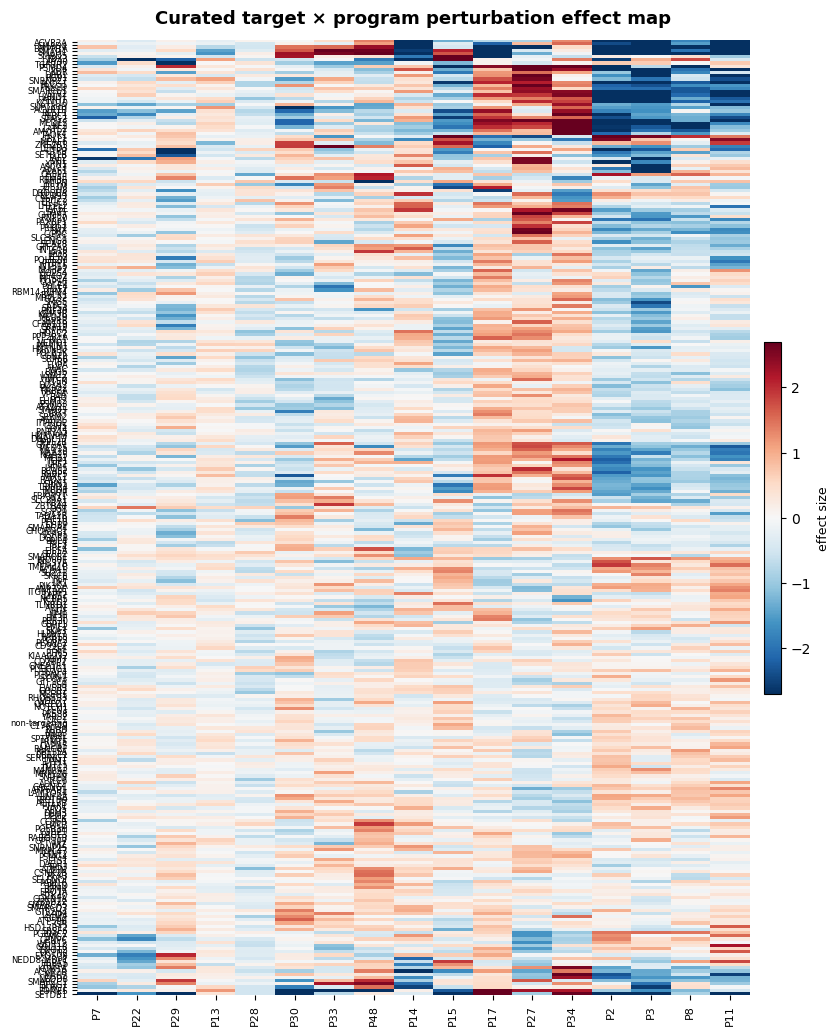

(<Figure size 850x1046.5 with 2 Axes>,
 <Axes: title={'center': 'Curated target × program perturbation effect map'}>)

In [6]:

# Order targets by hierarchical clustering on curated program effects.
row_order = cluster_rows(effect_mat)

plot_heatmap(
    effect_display,
    row_order=row_order,
    col_order=[program_label_map[p] for p in program_order if p in program_label_map],
    title="Curated target × program perturbation effect map",
    figsize=(8.5, max(6, 0.035 * len(row_order))),
    out=os.path.join(OUTDIR, "heatmap_curated_target_by_program_effects")
)


## Curated program–program correlation heatmap

This summarizes which programs have similar target-level perturbation effects.

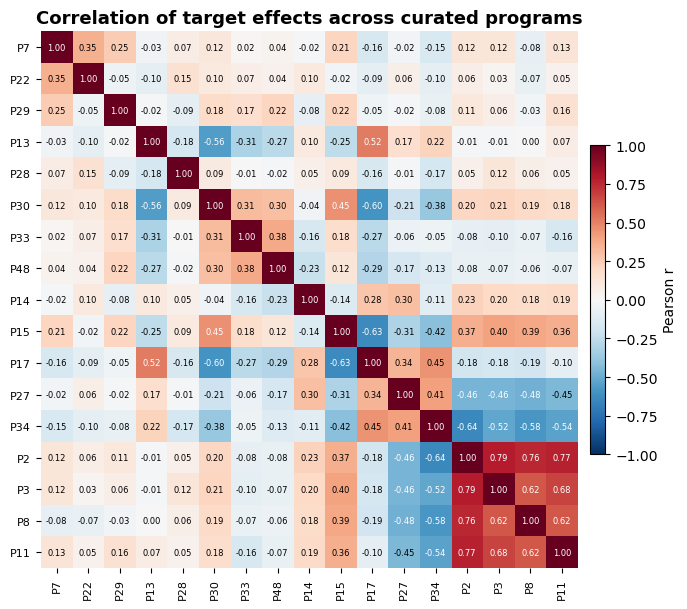

In [7]:

prog_corr = effect_mat.corr(method="pearson")
prog_corr_display = prog_corr.rename(index=program_label_map, columns=program_label_map)
prog_corr_display.to_csv(os.path.join(OUTDIR, "curated_program_program_pearson_correlation.csv"))

fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(prog_corr_display.values, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1))
ax.set_xticks(np.arange(prog_corr_display.shape[1]))
ax.set_yticks(np.arange(prog_corr_display.shape[0]))
ax.set_xticklabels(prog_corr_display.columns, rotation=90, fontsize=8)
ax.set_yticklabels(prog_corr_display.index, fontsize=8)
for i in range(prog_corr_display.shape[0]):
    for j in range(prog_corr_display.shape[1]):
        ax.text(j, i, f"{prog_corr_display.iloc[i,j]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(prog_corr_display.iloc[i,j]) > 0.45 else "black")
ax.set_title("Correlation of target effects across curated programs", fontsize=13, fontweight="bold")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="Pearson r")
for spine in ax.spines.values(): spine.set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR, "heatmap_curated_program_correlations.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(OUTDIR, "heatmap_curated_program_correlations.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(OUTDIR, "heatmap_curated_program_correlations.svg"), bbox_inches="tight")
plt.show()


## Selected program-effect scatter plots

These reproduce the core pairwise logic using the curated program vocabulary.

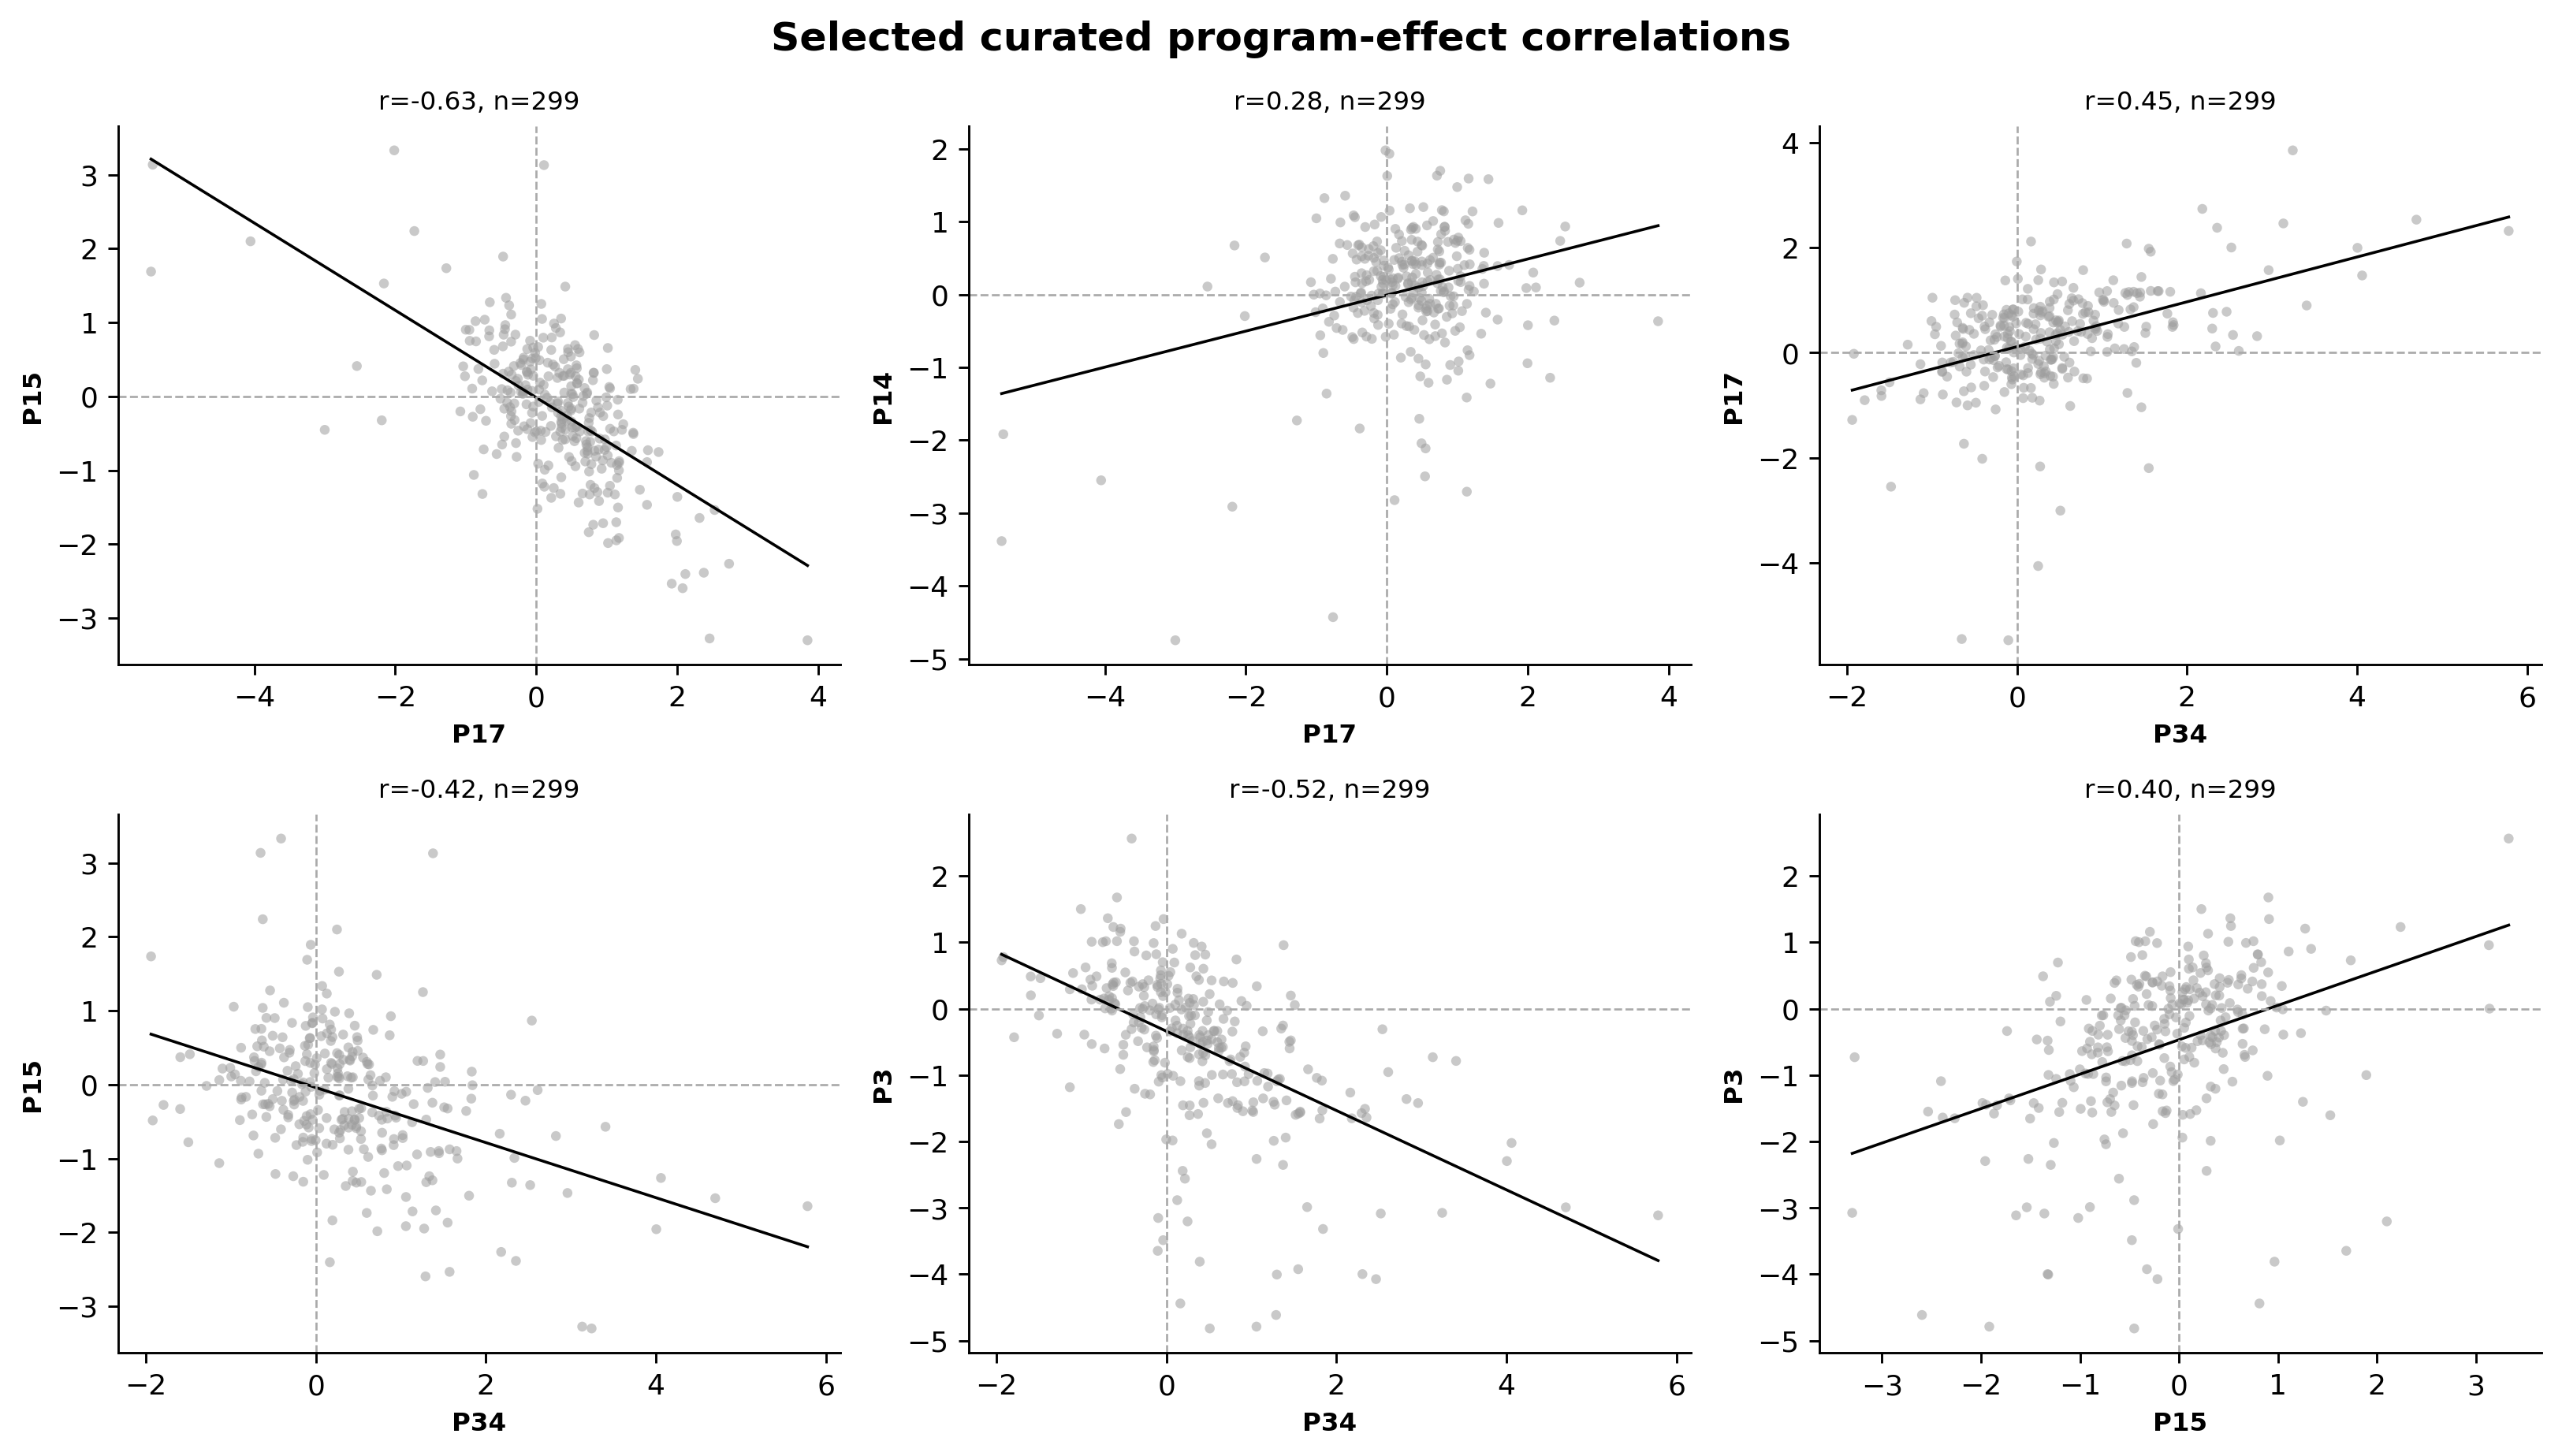

In [8]:

# Edit this list to add/remove selected program pairs.
selected_pairs = [
    (17, 15),  # P17 vs P15
    (17, 14),  # P17 vs P14
    (34, 17),  # P34 vs P17
    (34, 15),  # P34 vs P15
    (34, 3),   # P34 vs P3
    (15, 3),   # P15 vs P3
]

n = len(selected_pairs)
fig, axes = plt.subplots(2, int(np.ceil(n/2)), figsize=(4.2 * int(np.ceil(n/2)), 7.2), dpi=260)
axes = np.ravel(axes)
scatter_stats = []

for ax, (xpid, ypid) in zip(axes, selected_pairs):
    if xpid not in effect_mat.columns or ypid not in effect_mat.columns:
        ax.axis('off')
        continue
    dat = effect_mat[[xpid, ypid]].dropna()
    x = dat[xpid]
    y = dat[ypid]
    r, p = pearsonr(x, y)
    scatter_stats.append({"x_program": xpid, "y_program": ypid, "pearson_r": r, "p_value": p, "n_targets": len(dat)})
    ax.scatter(x, y, s=12, color="#9E9E9E", alpha=0.55, edgecolor='none')
    coef = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, coef[0]*xs + coef[1], color="black", lw=1.0)
    ax.axhline(0, ls="--", lw=0.75, color="#AAAAAA")
    ax.axvline(0, ls="--", lw=0.75, color="#AAAAAA")
    ax.set_xlabel(program_label_map.get(xpid, f"P{xpid}"), fontsize=9, fontweight="bold")
    ax.set_ylabel(program_label_map.get(ypid, f"P{ypid}"), fontsize=9, fontweight="bold")
    ax.set_title(f"r={r:.2f}, n={len(dat)}", fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
for ax in axes[len(selected_pairs):]: ax.axis('off')
fig.suptitle("Selected curated program-effect correlations", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR, "selected_curated_program_scatter_grid.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(OUTDIR, "selected_curated_program_scatter_grid.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(OUTDIR, "selected_curated_program_scatter_grid.svg"), bbox_inches="tight")
plt.show()

pd.DataFrame(scatter_stats).to_csv(os.path.join(OUTDIR, "selected_program_scatter_stats.csv"), index=False)


## Hippo-focused curated program heatmap

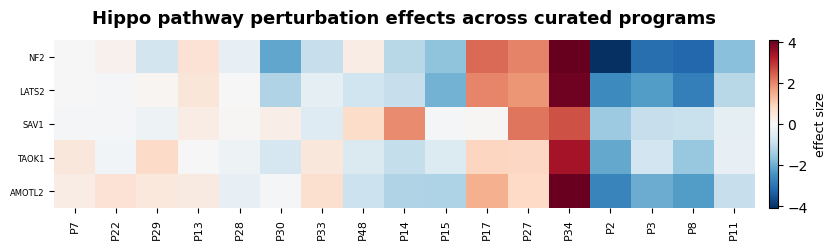

program_id,P7,P22,P29,P13,P28,P30,P33,P48,P14,P15,P17,P27,P34,P2,P3,P8,P11
target,,,,,,,,,,,,,,,,,
NF2,0.027714,0.163708,-0.760095,0.607610,-0.334877,-2.132423,-0.956764,0.305269,-1.143252,-1.646429,2.315363,2.042435,5.784222,-4.215380,-3.113956,-3.225021,-1.715960
LATS2,0.001584,-0.093478,0.087893,0.506336,-0.024056,-1.247685,-0.354718,-0.822964,-0.944340,-1.958334,1.994316,1.808796,4.005131,-2.629258,-2.295800,-2.824362,-1.148305
SAV1,-0.070338,-0.079317,-0.208587,0.317789,0.032466,0.279643,-0.542201,0.752652,1.930694,-0.075051,0.035276,2.188090,2.609087,-1.489415,-0.955159,-0.909506,-0.374188
TAOK1,0.463712,-0.103517,0.793897,-0.013884,-0.215227,-0.674759,0.453727,-0.594126,-0.967942,-0.571556,0.898157,0.859402,3.407411,-2.099793,-0.787577,-1.552222,-0.352442
AMOTL2,0.302581,0.603205,0.444814,0.359646,-0.341167,-0.072892,0.668298,-0.880114,-1.223517,-1.264540,1.468758,0.807143,4.060201,-2.697167,-2.022943,-2.287799,-0.951489


In [9]:

hippo_present = [g for g in HIPPO_TARGETS if g in effect_mat.index]
hippo_effect = effect_display.loc[hippo_present]

plot_heatmap(
    hippo_effect,
    row_order=hippo_present,
    col_order=[program_label_map[p] for p in program_order if p in program_label_map],
    title="Hippo pathway perturbation effects across curated programs",
    figsize=(8.5, 2.6),
    out=os.path.join(OUTDIR, "heatmap_hippo_curated_program_effects")
)

display(hippo_effect)


## Package outputs

In [10]:

import zipfile
zip_path = OUTDIR + ".zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(OUTDIR):
        for fn in files:
            fp = os.path.join(root, fn)
            z.write(fp, arcname=os.path.relpath(fp, OUTDIR))
print("Packaged:", zip_path)


Packaged: outputs_program_level_temporal_map_v4.zip
